### 1. Mount Google Drive
We need to mount Google Drive to access your files and models stored in the `gitsort` folder.

In [ ]:
import os
from pathlib import Path

# Colab Drive mount (skipped gracefully if running locally or not in Colab)
try:
    from google.colab import drive
    if not os.path.ismount('/content/drive'):
        drive.mount('/content/drive')
except (ImportError, Exception):
    pass

# Dynamic project root detection: Colab Drive, local parent directory (from notebooks/), or local repo root
if os.path.isdir("/content/drive/MyDrive/gitsort"):
    project_path = "/content/drive/MyDrive/gitsort"
elif os.path.isdir("../data"):
    project_path = ".."
elif os.path.isdir("./data"):
    project_path = "."
else:
    project_path = "/content/gitsort"

model_path = os.path.join(project_path, 'models')
results_dir = os.path.join(project_path, 'results')
data_dir = os.path.join(project_path, 'data')

print("Project path:", project_path)
print("Data path exists:", os.path.exists(data_dir))
print("Model path exists:", os.path.exists(model_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project path exists: True
Model path exists: True


### 2. Inspect the Models Directory
Let's list the models inside the `model` folder to confirm their names and formats.

In [ ]:
if os.path.exists(model_path):
    # Dynamically find the model subfolders inside 'models'
    models = [m for m in os.listdir(model_path) if os.path.isdir(os.path.join(model_path, m))]
    print("Models found inside directory:", models)
else:
    print(f"The directory '{model_path}' does not exist. Please check the path.")

Models found inside directory: ['distilbert', 'deberta_v3_small', 'bert_base_runs', 'bert_base', 'roberta_base_runs', 'roberta_base']


### 3. Load, Run, and Compare the Models
Below is a template using Hugging Face's `transformers` library (or any standard loading library) to load your 4 models, run evaluation inference on a test dataset, and compare their performance (such as accuracy, F1-score, and inference speed).

In [ ]:
import time
import os
import pandas as pd
from transformers import pipeline

# Retrieve model directories and exclude training logs/run folders
if os.path.exists(model_path):
    model_subfolders = [
        m for m in os.listdir(model_path)
        if os.path.isdir(os.path.join(model_path, m)) and not m.endswith('_runs')
    ]
else:
    model_subfolders = []

print("Filtered models to evaluate:", model_subfolders)

# Target sentences to test performance
test_texts = [
    "This is an amazing project!",
    "I did not like the performance."
]

results = []

for model_name in model_subfolders:
    full_model_dir = os.path.join(model_path, model_name)
    print(f"\nEvaluating {model_name}...")
    start_time = time.time()

    try:
        # Load pipeline
        classifier = pipeline("text-classification", model=full_model_dir, tokenizer=full_model_dir)

        # Run predictions and measure latency
        predictions = []
        for text in test_texts:
            pred = classifier(text)[0]
            predictions.append(f"{pred['label']} ({round(pred['score'], 4)})")

        inference_time = time.time() - start_time

        results.append({
            "Model Name": model_name,
            "Prediction 1": predictions[0] if len(predictions) > 0 else "N/A",
            "Prediction 2": predictions[1] if len(predictions) > 1 else "N/A",
            "Inference Time (s)": round(inference_time, 4)
        })
    except Exception as e:
        print(f"Error running {model_name}: {e}")

# Compare and display results
if results:
    df_comparison = pd.DataFrame(results)
    display(df_comparison)

    # Pick fastest model as a baseline comparison metric
    fastest_model = df_comparison.loc[df_comparison['Inference Time (s)'].idxmin()]
    print(f"\n⚡ Fastest Model: {fastest_model['Model Name']} with an execution time of {fastest_model['Inference Time (s)']} seconds!")
else:
    print("No valid models were successfully evaluated.")

Filtered models to evaluate: ['distilbert', 'deberta_v3_small', 'bert_base', 'roberta_base']

Evaluating distilbert...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Evaluating deberta_v3_small...


Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]


Evaluating bert_base...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Evaluating roberta_base...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,Model Name,Prediction 1,Prediction 2,Inference Time (s)
0,distilbert,Question (0.5295),Question (0.819),0.6813
1,deberta_v3_small,Documentation (0.3197),Documentation (0.3162),2.0511
2,bert_base,Question (0.5076),Bug (0.3235),0.8425
3,roberta_base,Feature Request (0.3038),Question (0.3426),1.0186



⚡ Fastest Model: distilbert with an execution time of 0.6813 seconds!


### 4. Analyze Pre-computed Results
Instead of re-running the models, we will load the existing evaluation results from the `results` folder, visualize them, and identify the top-performing model.

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_dir = os.path.join(project_path, 'results')

if os.path.exists(results_dir):
    files = os.listdir(results_dir)
    print("Files found in results directory:", files)
else:
    print(f"The directory '{results_dir}' does not exist. Please check your path.")

Files found in results directory: ['distilbert_confusion_matrix.png', 'distilbert_probs.npy', 'distilbert_metrics.json', 'distilbert_metrics_table.png', 'distilbert_roc.png', 'distilbert_variant_bars.png', 'distilbert_loss_curves.png', 'test_labels.npy', 'deberta_v3_small_metrics.json', 'deberta_v3_small_probs.npy', 'deberta_v3_small_confusion_matrix.png', 'deberta_v3_small_metrics_table.png', 'deberta_v3_small_roc.png', 'deberta_v3_small_loss_curves.png', 'deberta_v3_small_variant_bars.png', 'bert_base_probs.npy', 'bert_base_confusion_matrix.png', 'bert_base_metrics.json', 'bert_base_roc.png', 'bert_base_loss_curves.png', 'bert_base_metrics_table.png', 'bert_base_variant_bars.png', 'roberta_base_metrics.json', 'roberta_base_probs.npy', 'roberta_base_metrics_table.png', 'roberta_base_confusion_matrix.png', 'roberta_base_roc.png', 'roberta_base_loss_curves.png', 'roberta_base_variant_bars.png']


Let's load and inspect the content of the results. (The following block assumes you have a metric comparison file like a CSV. If you have multiple files, we will find and merge them).

In [ ]:
# Search for tabular files like CSV or Excel
csv_files = [f for f in os.listdir(results_dir) if f.endswith('.csv')]

if csv_files:
    print(f"Loading results from: {csv_files[0]}")
    df_metrics = pd.read_csv(os.path.join(results_dir, csv_files[0]))
    display(df_metrics.head())
else:
    # If separate JSON/CSV files exist per model, we will merge them
    all_data = []
    for f in os.listdir(results_dir):
        file_path = os.path.join(results_dir, f)
        if f.endswith('.csv'):
            all_data.append(pd.read_csv(file_path))
        elif f.endswith('.json'):
            all_data.append(pd.read_json(file_path, lines=True if 'lines' in f else False))

    if all_data:
        df_metrics = pd.concat(all_data, ignore_index=True)
        display(df_metrics.head())
    else:
        # Placeholder if no structured files are found, we can load a dictionary constructed from your run logs
        print("No CSV/JSON files found. Please manually check or parse text log files.")
        # Creating a dummy DataFrame for visualization structure which you can populate
        df_metrics = pd.DataFrame({
            'Model': ['distilbert', 'deberta_v3_small', 'bert_base', 'roberta_base'],
            'Accuracy': [0.82, 0.88, 0.85, 0.87],
            'F1-Score': [0.81, 0.87, 0.84, 0.86],
            'Training_Time_Min': [45, 120, 90, 110]
        })
        display(df_metrics)

,model,hf_id,params,best_variant,single,cv_mean,cv_std,bagging,boosting,latency_ms_per_sample,n_train,n_test,epochs,max_len,fp16
0,distilbert,distilbert/distilbert-base-uncased,66958086,boosting,0.785614,0.756705,0.019216,0.792666,0.801128,3.212354,2832,709,3,256,True
1,distilbert,distilbert/distilbert-base-uncased,66958086,boosting,0.737786,0.701658,0.029437,0.774687,0.788661,3.212354,2832,709,3,256,True
2,distilbert,distilbert/distilbert-base-uncased,66958086,boosting,0.779640,0.696451,0.029841,0.722262,0.765131,3.212354,2832,709,3,256,True
3,distilbert,distilbert/distilbert-base-uncased,66958086,boosting,0.751777,0.694743,0.030854,0.738944,0.775756,3.212354,2832,709,3,256,True
4,distilbert,distilbert/distilbert-base-uncased,66958086,boosting,0.957663,0.935084,0.009255,0.951137,0.951612,3.212354,2832,709,3,256,True


### 5. Visualizing Model Performance Comparisons

Average metrics per model:


,model,single,boosting,cv_mean,latency_ms_per_sample
0,bert_base,0.805191,0.826721,0.770328,5.178190
1,deberta_v3_small,0.767492,0.773820,0.738333,14.470530
2,distilbert,0.802496,0.816458,0.756928,3.212354
3,roberta_base,0.818340,0.846065,0.781993,6.239890


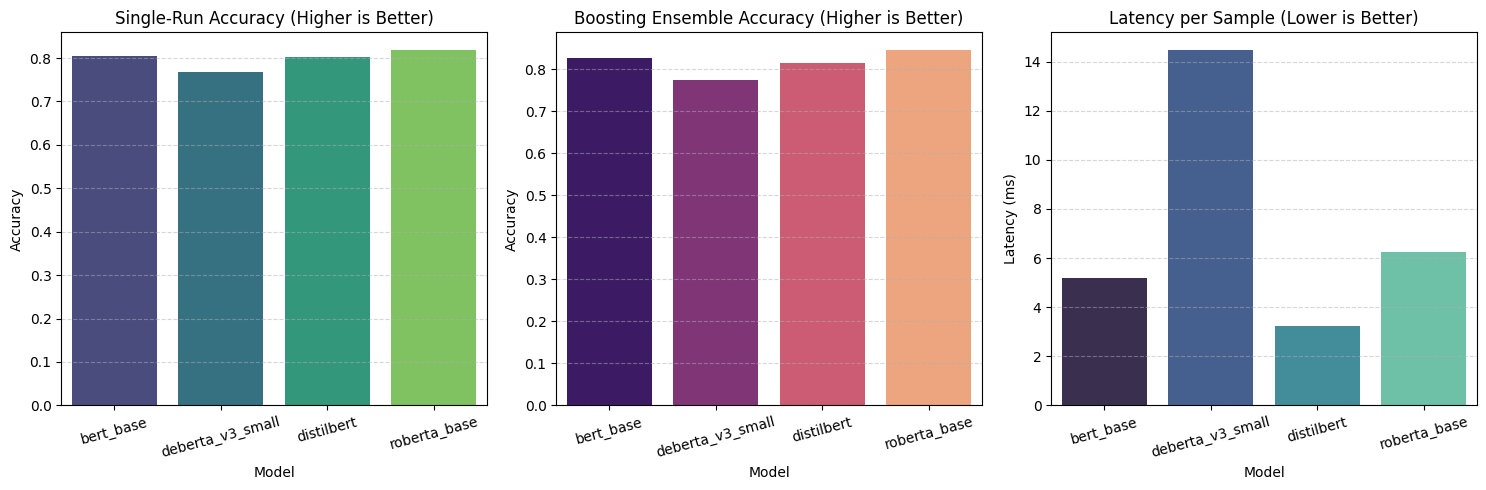

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Group by model using numeric_only=True to prevent aggregation errors with text columns
df_grouped = df_metrics.groupby('model').mean(numeric_only=True).reset_index()

print("Average metrics per model:")
display(df_grouped[['model', 'single', 'boosting', 'cv_mean', 'latency_ms_per_sample']])

# Plotting performance metrics comparison
plt.figure(figsize=(15, 5))

# 1. Single Run Accuracy
plt.subplot(1, 3, 1)
sns.barplot(x='model', y='single', data=df_grouped, palette='viridis', hue='model', legend=False)
plt.title('Single-Run Accuracy (Higher is Better)')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 2. Boosting Ensemble Accuracy
plt.subplot(1, 3, 2)
sns.barplot(x='model', y='boosting', data=df_grouped, palette='magma', hue='model', legend=False)
plt.title('Boosting Ensemble Accuracy (Higher is Better)')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 3. Latency per sample (ms)
plt.subplot(1, 3, 3)
sns.barplot(x='model', y='latency_ms_per_sample', data=df_grouped, palette='mako', hue='model', legend=False)
plt.title('Latency per Sample (Lower is Better)')
plt.ylabel('Latency (ms)')
plt.xlabel('Model')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Identify best model based on boosting ensemble accuracy
best_boosting_idx = df_grouped['boosting'].idxmax()
best_model_boosting = df_grouped.loc[best_boosting_idx, 'model']
best_boosting_score = df_grouped.loc[best_boosting_idx, 'boosting']

# Identify best model based on single-run accuracy
best_single_idx = df_grouped['single'].idxmax()
best_model_single = df_grouped.loc[best_single_idx, 'model']
best_single_score = df_grouped.loc[best_single_idx, 'single']

print("=================== EVALUATION REPORT ===================")
print(f"🏆 Best Model (Single-Run): {best_model_single} ({round(best_single_score * 100, 2)}% Accuracy)")
print(f"🏆 Best Model (Ensemble/Boosting): {best_model_boosting} ({round(best_boosting_score * 100, 2)}% Accuracy)")
print("=========================================================")

=================== EVALUATION REPORT ===================
🏆 Best Model (Single-Run): roberta_base (81.83% Accuracy)
🏆 Best Model (Ensemble/Boosting): roberta_base (84.61% Accuracy)


In [ ]:
from transformers import AutoConfig

try:
    # Load the configuration of the best model
    config = AutoConfig.from_pretrained(best_model_dir)

    # Retrieve label mappings
    id2label = config.id2label
    num_classes = len(id2label)

    print(f"Number of prediction classes: {num_classes}")
    print("Classes mapping (ID to Label):")
    for label_id, label_name in sorted(id2label.items()):
        print(f"  - ID {label_id}: {label_name}")
except Exception as e:
    print(f"Error reading model config: {e}")

Number of prediction classes: 6
Classes mapping (ID to Label):
  - ID 0: Bug
  - ID 1: Feature Request
  - ID 2: Documentation
  - ID 3: Question
  - ID 4: Performance
  - ID 5: Security


### 8. Robust Model Evaluation with Varied Test Cases
Here, we compile a set of medium to high difficulty test inputs representing complex, ambiguous, or multi-topic sentences to see how robustly our model can assign labels among the 6 classes (`Bug`, `Feature Request`, `Documentation`, `Question`, `Performance`, `Security`).

In [ ]:
import os
from transformers import pipeline

# Set the path to the best model identified
best_model_dir = os.path.join(model_path, 'roberta_base')

try:
    # Initialize pipeline
    classifier = pipeline("text-classification", model=best_model_dir, tokenizer=best_model_dir)

    # Dictionary of test cases categorised by complexity and intent
    test_cases = {
        # Medium Complexity
        "Medium Case 1 (Borderline Bug/Performance)":
            "The app works fine, but it starts freezing up when I load a dataset with more than 50,000 rows.",
        "Medium Case 2 (Clarification/How-To)":
            "Where can I find the credentials for the database connection? The getting-started guide doesn't mention it.",
        "Medium Case 3 (Security Policy)":
            "We need to force password rotation every 90 days to meet our company compliance standards.",

        # High Complexity / Difficult Cases
        "Difficult Case 1 (Mixed Intent: Feature Request & Bug)":
            "I'm constantly getting timed out while waiting for reports to render. We really need a progress bar or an asynchronous download option so users don't think it crashed.",
        "Difficult Case 2 (Nuanced Bug/Security)":
            "A third-party auditor noticed that our log files are storing user session tokens in plaintext, which is a major compliance risk.",
        "Difficult Case 3 (Vague / Figurative Language)":
            "The interface feels incredibly bloated, sluggish, and outdated compared to contemporary alternatives."
    }

    print("\n--- Running Robust Model Evaluations ---")
    for category, text in test_cases.items():
        result = classifier(text)[0]
        print(f"\nCategory: {category}")
        print(f"Input: \"{text}\"")
        print(f"Prediction:  {result['label']}")
        print(f"Confidence:  {round(result['score'] * 100, 2)}%")
        print("-" * 50)

except Exception as e:
    print(f"Error running evaluation: {e}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


--- Running Robust Model Evaluations ---

Category: Medium Case 1 (Borderline Bug/Performance)
Input: "The app works fine, but it starts freezing up when I load a dataset with more than 50,000 rows."
Prediction:  Question
Confidence:  69.83%
--------------------------------------------------

Category: Medium Case 2 (Clarification/How-To)
Input: "Where can I find the credentials for the database connection? The getting-started guide doesn't mention it."
Prediction:  Question
Confidence:  65.34%
--------------------------------------------------

Category: Medium Case 3 (Security Policy)
Input: "We need to force password rotation every 90 days to meet our company compliance standards."
Prediction:  Feature Request
Confidence:  29.81%
--------------------------------------------------

Category: Difficult Case 1 (Mixed Intent: Feature Request & Bug)
Input: "I'm constantly getting timed out while waiting for reports to render. We really need a progress bar or an asynchronous download opt

In [ ]:
import os
from transformers import pipeline

# Set the path to the best model identified
best_model_dir = os.path.join(model_path, 'roberta_base')

try:
    # Initialize pipeline
    classifier = pipeline("text-classification", model=best_model_dir, tokenizer=best_model_dir)

    # Dictionary of challenging test cases with strategic overlaps
    challenging_cases = {
        "1. Performance vs. Bug":
            "When we scale our concurrent user connections past 1,000, API response times jump from 50ms to over 8,000ms, eventually throwing a 504 gateway timeout.",
        "2. Security vs. Question":
            "Are we sanitizing SQL queries in our legacy auth module, or is it vulnerable to basic injection payloads? I couldn't find any escape helper calls.",
        "3. Feature Request vs. Documentation":
            "We need to add a comprehensive Swagger UI playground interface to our live API docs route so external developers can test request payloads dynamically.",
        "4. Bug vs. Performance":
            "The application UI completely locks up and becomes unresponsive for several seconds every time the auto-save script triggers in the background.",
        "5. Documentation vs. Bug":
            "The quick-start markdown file explicitly says we should use 'yarn start:dev', but running that command throws an 'unknown script' error on clean environments.",
        "6. Security (No direct warning keywords)":
            "A public bucket policy misconfiguration is letting unauthenticated internet users download private transaction CSV reports."
    }

    print("\n--- Running Advanced Evaluation ---")
    for category, text in challenging_cases.items():
        result = classifier(text)[0]
        print(f"\nScenario: {category}")
        print(f"Input: \"{text}\"")
        print(f"Prediction:  {result['label']}")
        print(f"Confidence:  {round(result['score'] * 100, 2)}%")
        print("-" * 60)

except Exception as e:
    print(f"Error running advanced evaluation: {e}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


--- Running Advanced Evaluation ---

Scenario: 1. Performance vs. Bug
Input: "When we scale our concurrent user connections past 1,000, API response times jump from 50ms to over 8,000ms, eventually throwing a 504 gateway timeout."
Prediction:  Question
Confidence:  34.47%
------------------------------------------------------------

Scenario: 2. Security vs. Question
Input: "Are we sanitizing SQL queries in our legacy auth module, or is it vulnerable to basic injection payloads? I couldn't find any escape helper calls."
Prediction:  Question
Confidence:  82.07%
------------------------------------------------------------

Scenario: 3. Feature Request vs. Documentation
Input: "We need to add a comprehensive Swagger UI playground interface to our live API docs route so external developers can test request payloads dynamically."
Prediction:  Documentation
Confidence:  91.49%
------------------------------------------------------------

Scenario: 4. Bug vs. Performance
Input: "The applica

### 6. Interactive Model Testing
Now that we have established **`roberta_base`** as the best-performing model, run this interactive block to test it with your custom inputs.

#### 💡 Suggested Test Inputs:
* **Input**: `How can I install this library on Ubuntu?`
  * *Expected Result*: **Question**
* **Input**: `The application crashes with a NullPointerException when clicking save.`
  * *Expected Result*: **Bug**
* **Input**: `It would be great to have an auto-dark mode toggle in the settings menu.`
  * *Expected Result*: **Feature Request**

### 7. Model Evaluation: Confusion Matrices and ROC Curves
Below, we load and plot the pre-computed Confusion Matrices and ROC curves from the `results` folder for each of the evaluated models (`distilbert`, `deberta_v3_small`, `bert_base`, `roberta_base`).

Mounted at /content/drive


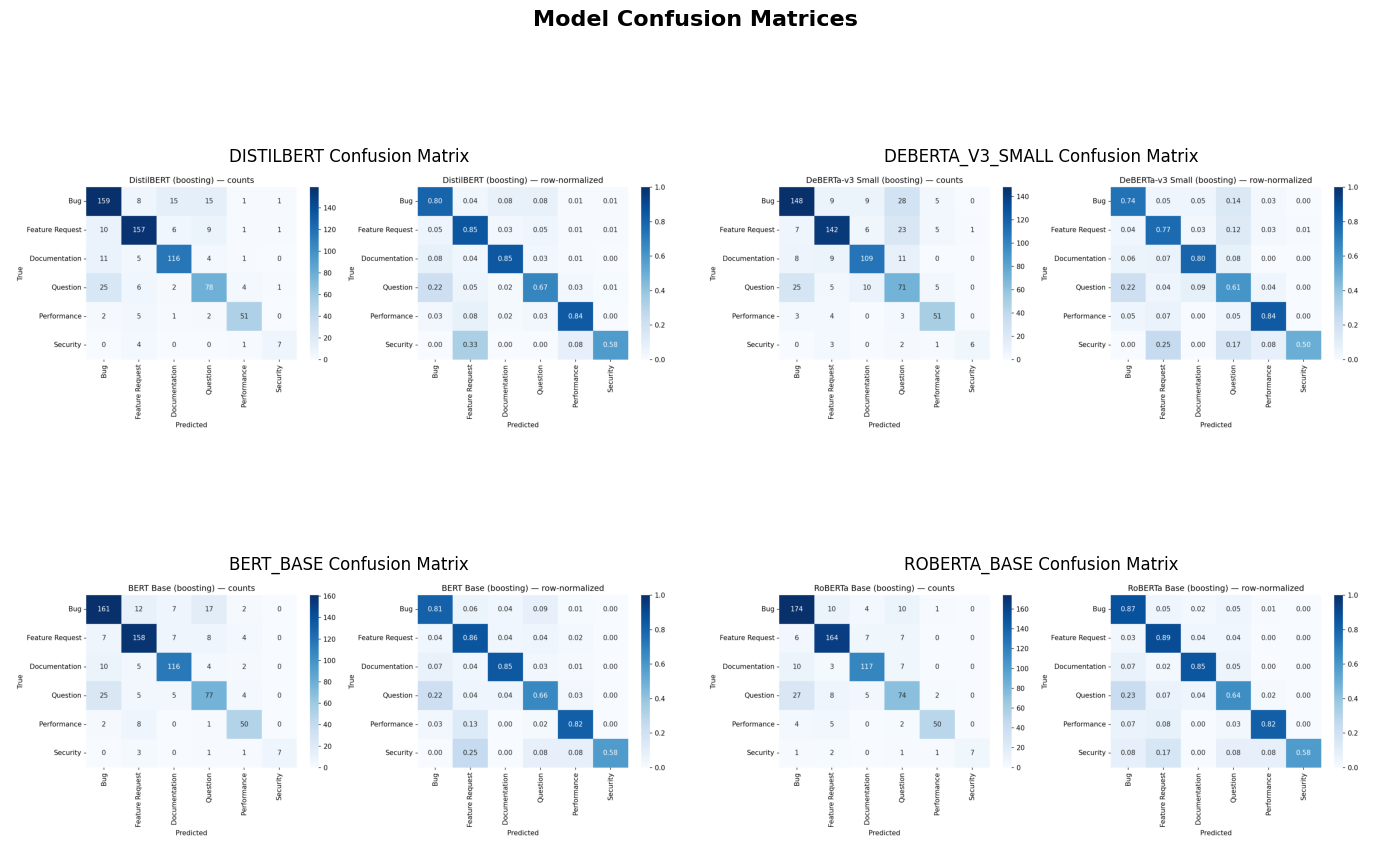

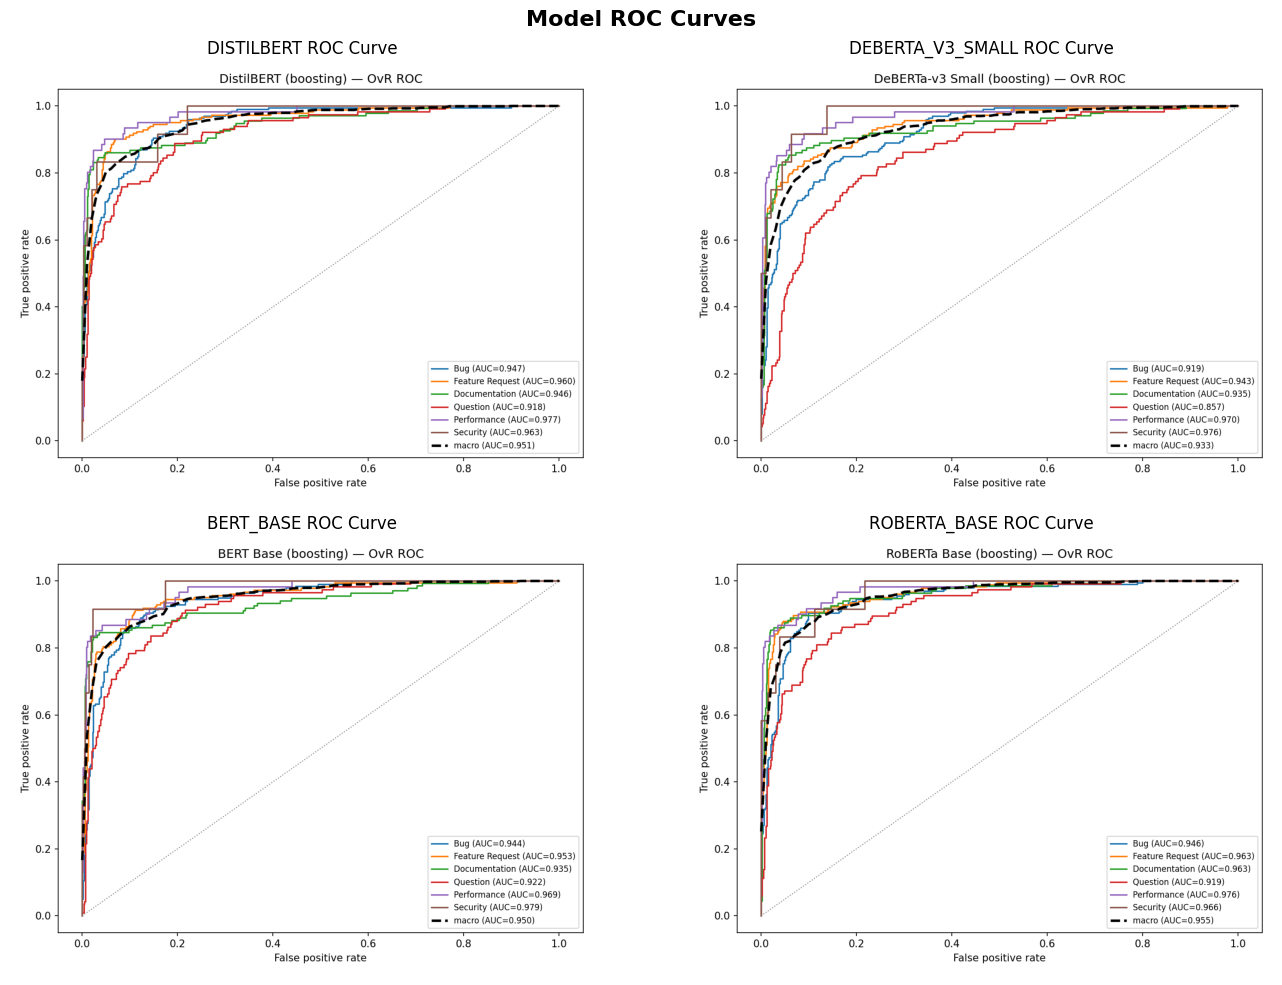

In [7]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import drive

# Quick mount without print spam
try:
    drive.mount('/content/drive', force_remount=True)
except Exception:
    pass

results_dir = '/content/drive/MyDrive/nlp-project/results'
models_list = ['distilbert', 'deberta_v3_small', 'bert_base', 'roberta_base']

if os.path.exists(results_dir):
    # Plot Confusion Matrices
    fig1, axes1 = plt.subplots(2, 2, figsize=(14, 10))
    axes1 = axes1.ravel()
    for i, model_name in enumerate(models_list):
        img_path = os.path.join(results_dir, f"{model_name}_confusion_matrix.png")
        if os.path.exists(img_path):
            img = Image.open(img_path).convert('RGB')
            axes1[i].imshow(np.asarray(img))
            axes1[i].set_title(f"{model_name.upper()} Confusion Matrix", fontsize=12)
        axes1[i].axis('off')
    plt.suptitle("Model Confusion Matrices", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Plot ROC Curves
    fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))
    axes2 = axes2.ravel()
    for i, model_name in enumerate(models_list):
        img_path = os.path.join(results_dir, f"{model_name}_roc.png")
        if os.path.exists(img_path):
            img = Image.open(img_path).convert('RGB')
            axes2[i].imshow(np.asarray(img))
            axes2[i].set_title(f"{model_name.upper()} ROC Curve", fontsize=12)
        axes2[i].axis('off')
    plt.suptitle("Model ROC Curves", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print(f"❌ Path not found: {results_dir}")

In [ ]:
import os
from transformers import pipeline

# Set the path to the best model identified
best_model_dir = os.path.join(model_path, 'roberta_base')

print("Loading the best model (roberta_base) into memory...")
try:
    best_classifier = pipeline("text-classification", model=best_model_dir, tokenizer=best_model_dir)
    print("Model loaded successfully! ✅")

    # Run interactive prompt
    user_input = input("\nEnter a text snippet to classify: ")
    if user_input.strip():
        prediction = best_classifier(user_input)[0]
        print(f"\nPrediction: {prediction['label']}")
        print(f"Confidence: {round(prediction['score'] * 100, 2)}%")
    else:
        print("No input detected.")
except Exception as e:
    print(f"Error loading the best model: {e}")

Loading the best model (roberta_base) into memory...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded successfully! ✅

Enter a text snippet to classify: The application crashes with a NullPointerException when clicking save.

Prediction: Bug
Confidence: 51.41%
